In [ ]:
from pathlib import Path

import matplotlib.pyplot as plt
import torch
import torchinfo
import torchtext
import torchtext.transforms as T
from torch import nn, optim
from torch.utils.data import DataLoader
from torchlake.common.helpers.tokenizer import CharNgramTokenizer
from torchlake.common.helpers.transform import CustomVocabTransform
from torchlake.common.helpers.vocab import CharNgramVocab
from torchlake.common.schemas.nlp import NLPContext
from torchlake.common.utils.file import read_json_file, write_json_file
from torchlake.common.utils.platform import get_file_size, get_num_workers
from torchlake.common.utils.text import (
    build_vocab,
    get_context,
    get_unigram_counts,
    is_corpus_title,
    is_longer_text,
)
from torchlake.language_model.constants.enum import LossType, Word2VecModelType
from torchlake.language_model.controller.trainer_word2vec import (
    CBOWTrainer,
    SkipGramTrainer,
)
from torchlake.language_model.models.subword import SubwordLM
from torchlake.language_model.models.word2vec.loss import (
    HierarchicalSoftmax,
    NegativeSampling,
)
from torchlake.language_model.models.word2vec import (
    subsampling_probability,
    subsampling,
)
from torchtext.data.utils import get_tokenizer, ngrams_iterator
import datasets
from datasets import load_dataset
from tqdm import tqdm

d:\research\pytorch-implementations\gits\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
torch.__version__

'2.8.0+cu126'

# setting


In [3]:
DATASET_NAME = "wikiText2"

In [4]:
artifact_path = Path("../../artifacts/subword-lm")
artifact_path.mkdir(exist_ok=True)

artifact_dataset_path = artifact_path / DATASET_NAME
artifact_dataset_path.mkdir(exist_ok=True)

data_path = Path("../../data/hf")

In [5]:
CONTEXT = NLPContext()

In [6]:
BATCH_SIZE = 32
CONTEXT_SIZE = 5

In [7]:
DEVICE = torch.device(CONTEXT.device)

In [8]:
BUCKET_SIZE = 10**5  # should be smaller than vocab size + ngram size

In [9]:
tokenizer = get_tokenizer("basic_english")

In [11]:
ngram_vocab = CharNgramVocab(context=CONTEXT, bucket_size=BUCKET_SIZE)
ngram_tokenizer = CharNgramTokenizer(tokenizer, ngram_vocab, ngrams=[2])

In [ ]:
def dataset_factory(
    dataset,
    context_size: int = 1,
    ngram_transform=None,
    word_transform=None,
    word_spans_transform=None,
):
    dataset = (
        dataset.map(lambda text: text.strip())
        .map(lambda text: text.lower())
        .filter(lambda text: is_longer_text(text, context_size))
        .filter(lambda text: not is_corpus_title(text))
        .map(ngram_tokenizer)
    )

    if ngram_transform:
        dataset = dataset.map(
            lambda row: (
                ngram_transform(row[0]),
                word_transform(row[1]),
                word_spans_transform(row[2]),
            )  # (grams, words, word_spans)
        )

    return dataset

In [ ]:
train_dataset = load_dataset(
    "Salesforce/wikitext", name=DATASET_NAME, cache_dir=data_path, split="train"
)
# val_dataset = load_dataset(
#     "Salesforce/wikitext", name=DATASET_NAME, cache_dir=data_path, split="validation"
# )
# test_dataset = load_dataset(
#     "Salesforce/wikitext", name=DATASET_NAME, cache_dir=data_path, split="test"
# )

In [ ]:
cloned_train_dataset = dataset_factory(train_dataset, CONTEXT_SIZE)
for _ in cloned_train_dataset:
    pass

In [ ]:
def dataset_factory_for_vocab(dataset, minimum_length: int = 1):
    dataset = (
        dataset.map(lambda text: text.strip())
        .map(lambda text: text.lower())
        .filter(lambda text: is_longer_text(text, minimum_length))
        .map(lambda text: ngram_tokenizer.tokenizer(text))
    )

    return dataset

In [ ]:
# optional for KNN search
ngram_vocab.build_word_vocab(
    datapipe_factory_for_vocab(train_dataset, minimum_length=CONTEXT_SIZE)
)

In [ ]:
VOCAB_SIZE = len(ngram_vocab.word_vocab)
VOCAB_SIZE

20408

In [ ]:
print("cache size:", len(ngram_vocab))

cache size: 31279


In [ ]:
ngram_vocab.save_word_vocab(artifact_dataset_path / "words.json")
ngram_vocab.save_subword_vocab(artifact_dataset_path / "grams.json")

In [ ]:
ngram_vocab.load_word_vocab(artifact_dataset_path / "words.json")
ngram_vocab.load_subword_vocab(artifact_dataset_path / "grams.json")

In [ ]:
get_file_size(artifact_dataset_path / "words.json")

'0.34MB'

In [ ]:
get_file_size(artifact_dataset_path / "grams.json")

'0.53MB'

In [ ]:
ngram_transform = T.Sequential(
    CustomVocabTransform(ngram_vocab),
    T.ToTensor(),
)

In [ ]:
word_transform = T.Sequential(
    T.Truncate(CONTEXT.max_seq_len),
    # T.Truncate(CONTEXT.max_seq_len - 2),
    T.ToTensor(),
    # T.AddToken(token=CONTEXT.bos_idx, begin=True),
    # T.AddToken(token=CONTEXT.eos_idx, begin=False),
    T.PadTransform(CONTEXT.max_seq_len, CONTEXT.padding_idx),
)

In [ ]:
word_spans_transform = T.Sequential(
    T.Truncate(CONTEXT.max_seq_len),
    T.ToTensor(),
)

In [ ]:
train_dataset = dataset_factory(
    train_dataset,
    CONTEXT_SIZE,
    ngram_transform,
    word_transform,
    word_spans_transform,
)

# val_dataset = dataset_factory(
#     val_dataset,
#     CONTEXT_SIZE,
#     ngram_transform,
#     word_transform,
#     word_spans_transform,
# )

# test_dataset = dataset_factory(
#     test_dataset,
#     CONTEXT_SIZE,
#     ngram_transform,
#     word_transform,
#     word_spans_transform,
# )

In [ ]:
count = 0
for grams, words, word_lengths in train_datapipe:
    print(grams.shape, words.shape, word_lengths.shape)
    if count > 10:
        break
    count += 1

torch.Size([453]) torch.Size([256]) torch.Size([123])
torch.Size([349]) torch.Size([256]) torch.Size([93])
torch.Size([382]) torch.Size([256]) torch.Size([103])
torch.Size([812]) torch.Size([256]) torch.Size([213])
torch.Size([1050]) torch.Size([256]) torch.Size([256])
torch.Size([326]) torch.Size([256]) torch.Size([83])
torch.Size([691]) torch.Size([256]) torch.Size([182])
torch.Size([790]) torch.Size([256]) torch.Size([222])
torch.Size([703]) torch.Size([256]) torch.Size([205])
torch.Size([979]) torch.Size([256]) torch.Size([256])
torch.Size([961]) torch.Size([256]) torch.Size([252])
torch.Size([1064]) torch.Size([256]) torch.Size([256])


In [ ]:
NUM_WORKERS = get_num_workers()

In [ ]:
def ngram_collate_fn(
    batch: list[torch.Tensor],
    device: torch.device,
) -> tuple[list[torch.Tensor], list[torch.Tensor], list[torch.Tensor], torch.Tensor]:
    gram_ngrams, gram_words, gram_word_spans = [], [], []
    context_ngrams, context_words, context_word_spans = [], [], []

    for (
        gram_ngram,
        gram_word,
        gram_word_span,
        context_ngram,
        context_word,
        context_sword_span,
    ) in batch:
        # truncate ngram with word length
        # move to gpu here
        # TODO: more trackable some other days
        gram_ngrams.append(gram_ngram[: sum(gram_word_span)].to(device))
        gram_words.append(gram_word)
        gram_word_spans.append(gram_word_span.to(device))

        context_ngrams.append(context_ngram[: sum(context_sword_span)].to(device))
        context_words.append(context_word)
        context_word_spans.append(context_sword_span.to(device))

    return (
        gram_ngrams,
        torch.stack(gram_words).to(device),
        gram_word_spans,
        context_ngrams,
        torch.stack(context_words).to(device),
        context_word_spans,
    )

In [ ]:
from typing import Callable


def main_collate_fn(
    batch: list[torch.Tensor],
    device: torch.device,
    context_fn: Callable,
) -> tuple[
    list[torch.Tensor],
    list[torch.Tensor],
    list[torch.Tensor],
    list[torch.Tensor],
    list[torch.Tensor],
    list[torch.Tensor],
]:
    return ngram_collate_fn(batch, device)

In [ ]:
collate_fn = lambda data: main_collate_fn(
    data,
    DEVICE,
    context_fn=lambda data: get_context(
        data,
        CONTEXT_SIZE // 2,
        CONTEXT_SIZE // 2,
        enable_random_context_size=False,  # you can enable random context size for skipgram
    ),
)

train_dataloader = DataLoader(
    train_datapipe,
    batch_size=BATCH_SIZE,
    collate_fn=collate_fn,
    # pin_memory=True,
    num_workers=NUM_WORKERS,
)

val_dataloader = DataLoader(
    val_datapipe,
    batch_size=BATCH_SIZE,
    collate_fn=collate_fn,
    # pin_memory=True,
    num_workers=NUM_WORKERS,
)

test_dataloader = DataLoader(
    test_datapipe,
    batch_size=BATCH_SIZE,
    collate_fn=collate_fn,
    # pin_memory=True,
    num_workers=NUM_WORKERS,
)

In [ ]:
# check context size
# for data in train_datapipe:
#     if len(data) < 5:
#         print(data)
#         break

In [ ]:
# sample
# for data in train_datapipe:
#     if len(data) > 5:
#         print(data)
#         print(vocab.lookup_tokens(data))
#         break

In [ ]:
# count = 0
# for data in train_datapipe:
#   count += len(data)
# count

In [ ]:
# number of words in training corpurs
# wikitext2 count 1,993,228
# wikitext103 count 101,227,641

In [ ]:
count = 0
for (
    gram_grams,
    gram_words,
    gram_word_spans,
    context_grams,
    context_words,
    context_word_spans,
) in train_dataloader:
    print(len(gram_grams), *[gram_gram.shape for gram_gram in gram_grams[:4]])
    print(gram_words.shape)
    print(
        len(gram_word_spans),
        *[gram_word_span.shape for gram_word_span in gram_word_spans[:4]],
    )
    print(
        len(context_grams), *[context_gram.shape for context_gram in context_grams[:4]]
    )
    print(context_words.shape)
    print(
        len(context_word_spans),
        *[context_word_span.shape for context_word_span in context_word_spans[:4]],
    )
    if count > 10:
        break
    count += 1

torch.Size([32, 1, 252]) torch.Size([32, 4, 252])


# subsampling


In [ ]:
# load word frequency
# word_counts = read_json_file(artifact_dataset_path.joinpath("word-count.json"))
# word_counts = torch.LongTensor(word_counts)

In [ ]:
word_counts = get_unigram_counts(
    map(lambda x: x.tolist(), train_datapipe),
    VOCAB_SIZE,
    freq=False,
)

d:\research\pytorch-implementations\.venv\Lib\site-packages\torch\utils\data\datapipes\iter\combining.py:333: UserWarning: Some child DataPipes are not exhausted when __iter__ is called. We are resetting the buffer and each child DataPipe will read from the start again.
  warnings.warn("Some child DataPipes are not exhausted when __iter__ is called. We are resetting "


In [ ]:
word_freqs = word_counts / sum(word_counts)

In [ ]:
word_freqs.shape

torch.Size([20351])

In [ ]:
sum(word_freqs)

tensor(1.0001)

In [ ]:
sum(word_counts)

tensor(4468736)

In [ ]:
subsampling_threshold = 1e-5

In [ ]:
word_probs = (
    subsampling_probability(word_freqs, subsampling_threshold)
    .maximum(torch.zeros((1)))  # avoid negative number
    .to(DEVICE)
)

In [ ]:
# the formula itself does not need normalization
sum(word_probs)

tensor(1505.4606, device='cuda:0')

Text(0, 0.5, 'drop probability')

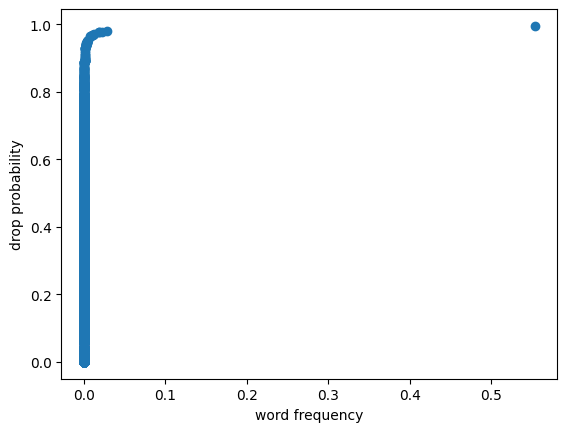

In [ ]:
plt.scatter(word_freqs, word_probs.cpu())
plt.xlabel("word frequency")
plt.ylabel("drop probability")

In [ ]:
# save word frequency
# write_json_file(
#     artifact_wikitext2_path.joinpath("word-count.json"),
#     word_counts.tolist(),
# )

# training


In [ ]:
EMBED_DIM = 30

In [ ]:
EPOCHS = 20

## cross entropy


### SkipGram


batch size 32, context size 5

each epoch needs 2min, 11.6GB with 4 workers on linux

each epoch needs 73min, 11.6GB with none workers on windows

In [ ]:
model = SubwordLM(
    BUCKET_SIZE,
    VOCAB_SIZE,
    EMBED_DIM,
    model_type=Word2VecModelType.SKIP_GRAM,
    context=CONTEXT,
).to(DEVICE)

In [63]:
torchinfo.summary(model)

Layer (type:depth-idx)                   Param #
Word2Vec                                 --
├─Linear: 1-1                            6,125,651
├─SkipGram: 1-2                          --
│    └─Embedding: 2-1                    6,105,300
Total params: 12,230,951
Trainable params: 12,230,951
Non-trainable params: 0

In [64]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=1e-3)

In [42]:
trainer = SkipGramTrainer(EPOCHS, DEVICE, feature_last=True)
training_loss = trainer.run(train_dataloader, model, optimizer, criterion, word_probs)

547it [02:20,  3.90it/s]


epoch 1 : 0.3087980635225172


547it [02:20,  3.91it/s]


epoch 2 : 0.3008768631164138


547it [02:02,  4.47it/s]


epoch 3 : 0.2930864764396255


... (31 outputs left out)

epoch 19 : 0.19922385570327697


547it [01:58,  4.61it/s]

epoch 20 : 0.1940036424521893


[0.3087980635225172,
 0.3008768631164138,
 0.2930864764396255,
 0.28571212783414873,
 0.2787685870140873,
 0.27227624281079915,
 0.2660893277221596,
 0.26012423175611593,
 0.2543126828183175,
 0.24859831043058966,
 0.2429566849108468,
 0.23735726671848245,
 0.2317677917937201,
 0.22624234862004147,
 0.22074919936309487,
 0.2153011620809571,
 0.20986061034456072,
 0.20452876289321348,
 0.19922385570327697,
 0.1940036424521893]

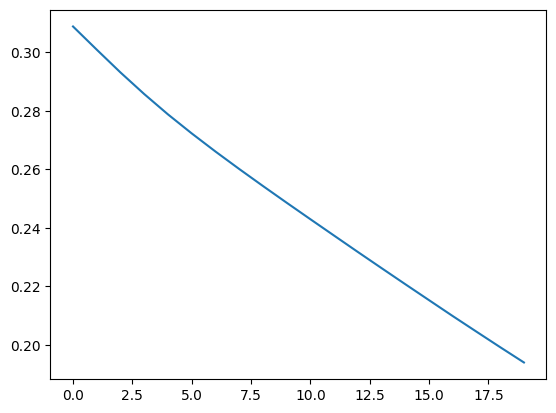

In [44]:
plt.plot(training_loss)

In [77]:
model_path = artifact_path / "sg.2.pth"

In [46]:
torch.save(model, model_path.as_posix())

In [78]:
model = torch.load(model_path.as_posix())

### CBOW


batch size 32, context size 5

each epoch needs 42s, 3.6GB with 4 workers on linux

each epoch needs 42s, 3.6GB with none workers on windows

In [38]:
model = Word2Vec(
    VOCAB_SIZE,
    EMBED_DIM,
    Word2VecModelType.CBOW,
    context=CONTEXT,
).to(DEVICE)

In [39]:
torchinfo.summary(model)

Layer (type:depth-idx)                   Param #
Word2Vec                                 --
├─Linear: 1-1                            6,125,651
├─CBOW: 1-2                              --
│    └─Embedding: 2-1                    6,105,300
Total params: 12,230,951
Trainable params: 12,230,951
Non-trainable params: 0

In [40]:
criterion = nn.CrossEntropyLoss()
optimizer = optim.SGD(model.parameters(), lr=1e-4)

In [ ]:
trainer = CbowTrainer(EPOCHS, DEVICE, feature_last=True)
training_loss = trainer.run(train_dataloader, model, optimizer, criterion, word_probs)

547it [00:46, 11.89it/s]


epoch 1 : 0.32005459873311354


547it [00:42, 12.78it/s]


epoch 2 : 0.31551956840877027


547it [00:42, 12.82it/s]


epoch 3 : 0.31102606066862015


... (30 outputs left out)

547it [00:33, 16.24it/s]


epoch 19 : 0.28306203162746624


547it [00:33, 16.26it/s]

epoch 20 : 0.2821944672836283


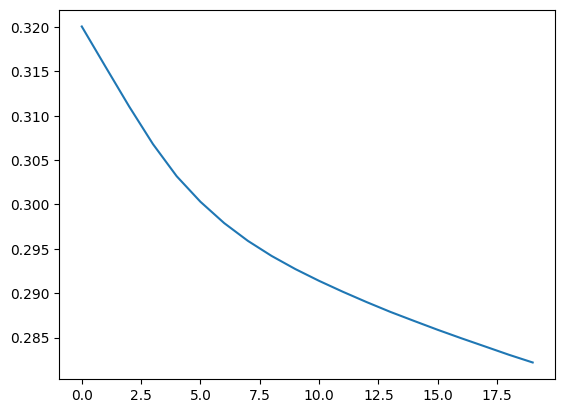

In [42]:
plt.plot(training_loss)

In [71]:
model_path = artifact_path / "cb.2.pth"

In [44]:
torch.save(model, model_path.as_posix())

In [72]:
model = torch.load(model_path.as_posix())

## NS


batch size 32, context size 5

each epoch needs 100s, 10GB with 4 workers on linux

each epoch needs 73m, 1.7GB with none workers on windows

each epoch needs 1m, 6GB with none workers on windows

### SkipGram


In [38]:
model = Word2Vec(
    VOCAB_SIZE,
    EMBED_DIM,
    Word2VecModelType.SKIP_GRAM,
    loss_type=LossType.NEGATIVE_SAMPLING,
    context=CONTEXT,
).to(DEVICE)

In [39]:
criterion = NegativeSampling(
    word_freqs,
    EMBED_DIM,
    VOCAB_SIZE,
    context=CONTEXT,
).to(DEVICE)
optimizer = optim.SGD([*model.parameters(), *criterion.parameters()], lr=1e-3)

In [40]:
trainer = SkipGramTrainer(EPOCHS, DEVICE)
training_loss = trainer.run(
    train_dataloader,
    model,
    optimizer,
    criterion,
    word_probs,
)

546it [01:04,  8.41it/s]


epoch 1 : 2485.2996221974176


546it [00:59,  9.15it/s]


epoch 2 : 1860.4642461537221


546it [00:59,  9.16it/s]


epoch 3 : 1637.0445704333395


... (30 outputs left out)

546it [00:58,  9.32it/s]


epoch 19 : 899.3524169921875


546it [00:58,  9.32it/s]

epoch 20 : 882.243330552532


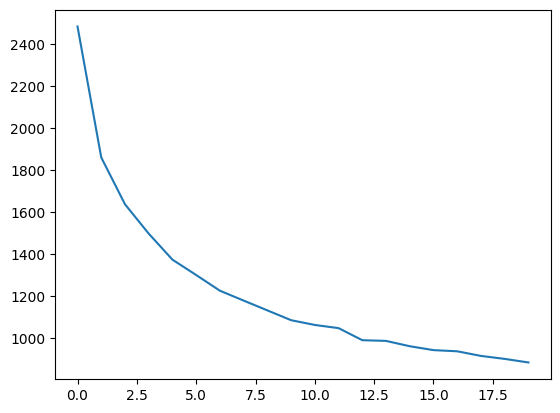

In [41]:
plt.plot(training_loss)

In [42]:
model_path = artifact_path / "sg-ns.3.nonrandom-context.pth"

In [43]:
torch.save(model.state_dict(), model_path.as_posix())

In [44]:
model.load_state_dict(torch.load(model_path.as_posix()))

<All keys matched successfully>

### CBOW


batch size 32, context size 5

__old__

each epoch needs 30s, 5.5GB with 4 workers on linux

each epoch needs 12min, 1.5GB with none workers on windows

__optimized 9/28/2024__

each epoch needs 20s, 2.2GB with none workers on windows

In [ ]:
model = SubwordLM(
    BUCKET_SIZE,
    VOCAB_SIZE,
    EMBED_DIM,
    model_type=Word2VecModelType.SKIP_GRAM,
    loss_type=LossType.NEGATIVE_SAMPLING,
    context=CONTEXT,
).to(DEVICE)

In [42]:
criterion = NegativeSampling(
    word_freqs,
    EMBED_DIM,
    VOCAB_SIZE,
    context=CONTEXT,
).to(DEVICE)
optimizer = optim.SGD([*model.parameters(), *criterion.parameters()], lr=1e-4)

In [ ]:
trainer = CBOWTrainer(EPOCHS, DEVICE)
training_loss = trainer.run(train_dataloader, model, optimizer, criterion, word_probs)

546it [00:22, 24.70it/s]


epoch 1 : 245.17482281343092


546it [00:20, 26.99it/s]


epoch 2 : 224.06546887643395


546it [00:20, 26.78it/s]


epoch 3 : 217.40091974553877


... (30 outputs left out)

546it [00:19, 27.48it/s]


epoch 19 : 190.0923442193721


546it [00:19, 27.70it/s]

epoch 20 : 189.37373910094487


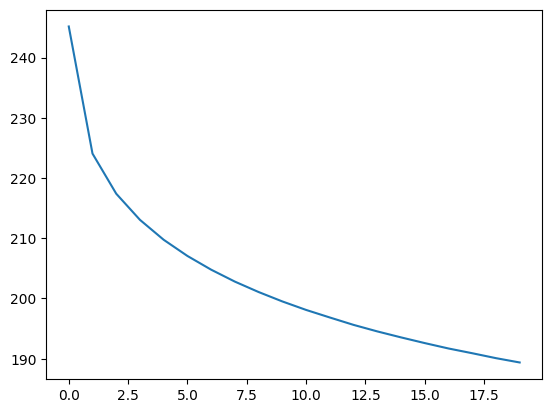

In [41]:
plt.plot(training_loss)

In [42]:
model_path = artifact_path / "cb-ns.3.pth"

In [44]:
torch.save(model.state_dict(), model_path.as_posix())

In [45]:
model.load_state_dict(torch.load(model_path.as_posix()))

<All keys matched successfully>

## HS


### SkipGram


batch size 32, context size 5

each epoch needs 50s, 7.5GB with 4 workers on linux

each epoch needs min, GB with none workers on windows

In [38]:
model = Word2Vec(
    VOCAB_SIZE,
    EMBED_DIM,
    Word2VecModelType.SKIP_GRAM,
    LossType.HIERARCHICAL_SOFTMAX,
    context=CONTEXT,
).to(DEVICE)

In [40]:
criterion = HierarchicalSoftmax(
    word_counts,
    EMBED_DIM,
    VOCAB_SIZE,
    context=CONTEXT,
).to(DEVICE)
optimizer = optim.SGD([*model.parameters(), *criterion.parameters()], lr=1e-3)

In [41]:
trainer = SkipGramTrainer(EPOCHS, DEVICE)
training_loss = trainer.run(train_dataloader, model, optimizer, criterion, word_probs)

546it [00:39, 13.89it/s]


epoch 1 : 0.1173579934455188


546it [00:39, 13.91it/s]


epoch 2 : 0.09393413118355652


546it [00:41, 13.31it/s]


epoch 3 : 0.08620688226330073


... (30 outputs left out)

546it [00:45, 12.07it/s]


epoch 19 : 0.06923326075514122


546it [00:46, 11.72it/s]

epoch 20 : 0.06876227408510954


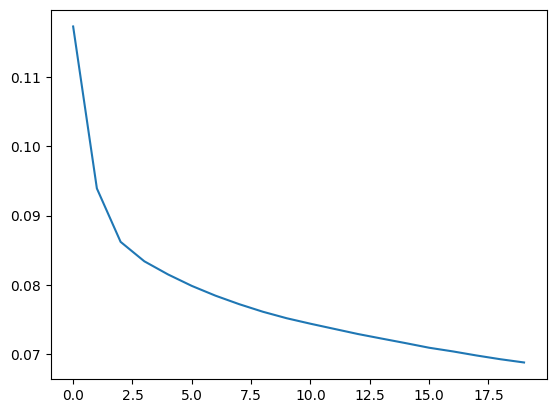

In [42]:
plt.plot(training_loss)

In [49]:
model_path = artifact_path / "sg-hs.2.random-context.pth"

In [44]:
torch.save(model, model_path.as_posix())

In [50]:
model = torch.load(model_path.as_posix())

### CBOW


batch size 32, context size 5

each epoch needs 15s, 3.3GB with 4 workers on linux

each epoch needs min, GB with none workers on windows

In [54]:
model = Word2Vec(
    VOCAB_SIZE,
    EMBED_DIM,
    Word2VecModelType.CBOW,
    LossType.HIERARCHICAL_SOFTMAX,
    context=CONTEXT,
).to(DEVICE)

In [56]:
criterion = HierarchicalSoftmax(
    word_counts,
    EMBED_DIM,
    VOCAB_SIZE,
    context=CONTEXT,
).to(DEVICE)
optimizer = optim.SGD([*model.parameters(), *criterion.parameters()], lr=1e-3)

In [57]:
trainer = CbowTrainer(EPOCHS, DEVICE)
training_loss = trainer.run(train_dataloader, model, optimizer, criterion, word_probs)

547it [00:17, 30.52it/s]


epoch 1 : 0.17942986124486252


547it [00:14, 37.03it/s]


epoch 2 : 0.1666779303692766


547it [00:14, 38.42it/s]


epoch 3 : 0.15994363399026157


... (31 outputs left out)

epoch 19 : 0.1294636450892299


547it [00:14, 38.48it/s]

epoch 20 : 0.12860948452427232


[0.17942986124486252,
 0.1666779303692766,
 0.15994363399026157,
 0.15522356833972373,
 0.1516314132649564,
 0.1485341561567226,
 0.1460283011416576,
 0.14376579286525493,
 0.14183737579340458,
 0.14019999233109487,
 0.13858588192847537,
 0.13716941925771295,
 0.13584011077443794,
 0.1346365648136567,
 0.1333807571889281,
 0.1323354737431931,
 0.13139466482439138,
 0.13044138926087334,
 0.1294636450892299,
 0.12860948452427232]

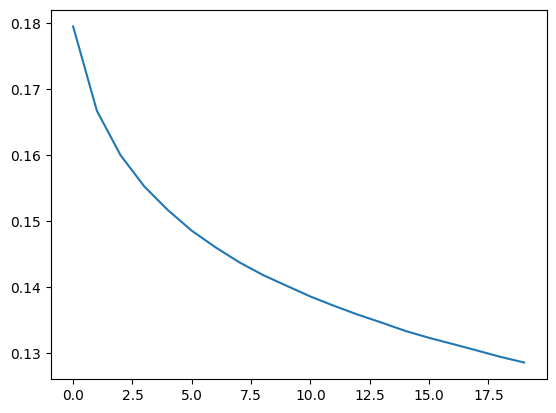

In [58]:
plt.plot(training_loss)

In [55]:
model_path = artifact_path / "cb-hs.2.pth"

In [60]:
torch.save(model, model_path.as_posix())

In [56]:
model = torch.load(model_path.as_posix())

# Evaluation


## word analogy


In [ ]:
from torchlake.language_model.datasets import WordAnalogyDataset

In [ ]:
analogy_data_path = Path("../../data") / "word-analogy"

In [48]:
dataset = WordAnalogyDataset(analogy_data_path)

In [49]:
dataset.data[:20]

[('Athens', 'Greece', 'Baghdad', 'Iraq'),
 ('Athens', 'Greece', 'Bangkok', 'Thailand'),
 ('Athens', 'Greece', 'Beijing', 'China'),
 ('Athens', 'Greece', 'Berlin', 'Germany'),
 ('Athens', 'Greece', 'Bern', 'Switzerland'),
 ('Athens', 'Greece', 'Cairo', 'Egypt'),
 ('Athens', 'Greece', 'Canberra', 'Australia'),
 ('Athens', 'Greece', 'Hanoi', 'Vietnam'),
 ('Athens', 'Greece', 'Havana', 'Cuba'),
 ('Athens', 'Greece', 'Helsinki', 'Finland'),
 ('Athens', 'Greece', 'Islamabad', 'Pakistan'),
 ('Athens', 'Greece', 'Kabul', 'Afghanistan'),
 ('Athens', 'Greece', 'London', 'England'),
 ('Athens', 'Greece', 'Madrid', 'Spain'),
 ('Athens', 'Greece', 'Moscow', 'Russia'),
 ('Athens', 'Greece', 'Oslo', 'Norway'),
 ('Athens', 'Greece', 'Ottawa', 'Canada'),
 ('Athens', 'Greece', 'Paris', 'France'),
 ('Athens', 'Greece', 'Rome', 'Italy'),
 ('Athens', 'Greece', 'Stockholm', 'Sweden')]

In [50]:
tokens = [[vocab[word.lower()] for word in pairs] for pairs in dataset.data]
tokens[:10]

[[12958, 6970, 18304, 5313],
 [12958, 6970, 9016, 6480],
 [12958, 6970, 10275, 1346],
 [12958, 6970, 4686, 1270],
 [12958, 6970, 0, 4409],
 [12958, 6970, 14016, 2280],
 [12958, 6970, 16617, 481],
 [12958, 6970, 14322, 1572],
 [12958, 6970, 17076, 6546],
 [12958, 6970, 0, 6575]]

In [51]:
tokens = torch.LongTensor([token for token in tokens if len(token) == 4]).to(DEVICE)

In [52]:
vectors = model.embeddings(tokens)

In [53]:
vectors.shape

torch.Size([19544, 4, 300])

In [54]:
# sg-ce: 0.08
# cb-ce: 0.08
# sg-ns: 0.038
# cbow-ns: 0.075
# sg-hs: 0.08
# cbow-hs: 0.08
metric = nn.CosineSimilarity()

country_a, capital_a, country_b, capital_b = vectors.transpose(0, 1)
score = metric(country_a - capital_a - country_b, -capital_b)
print(score.mean().item())

0.038399286568164825


## Simple QA / relationship inference

prove linear composability


In [ ]:
question = sentence_to_vector("berlin") - sentence_to_vector("germany")

In [ ]:
acc = 0

metric = nn.CosineSimilarity()
choices = [capital for capital, country in sample_word_pairs]
for capital, country in sample_word_pairs:
    print("question:", country)
    guess = metric(
        question + sentence_to_vector(country), sentence_to_vector(" ".join(choices))
    )
    # guess = metric(question, model.embeddings.weight)
    # print(guess)
    topk_guess_value, topk_guess_idx = guess.topk(3, largest=True)
    answer = [choices[g] for g in topk_guess_idx]
    print(topk_guess_value)
    # answer = vocab.lookup_tokens([guess[4:].abs().argmin()])
    print("answer:", answer)
    print("-------------------------------")

    acc += answer[0] == capital

print(f"{acc}/{len(sample_word_pairs)}")

question: france
tensor([0.5920, 0.0461, 0.0130], device='cuda:0')
answer: ['berlin', 'beijing', 'rome']
-------------------------------
question: china
tensor([0.5827, 0.0960, 0.0737], device='cuda:0')
answer: ['berlin', 'athens', 'beijing']
-------------------------------
question: russia
tensor([0.5642, 0.0994, 0.0861], device='cuda:0')
answer: ['berlin', 'beijing', 'paris']
-------------------------------
question: japan
tensor([0.5794, 0.0735, 0.0387], device='cuda:0')
answer: ['berlin', 'moscow', 'beijing']
-------------------------------
question: greece
tensor([0.5650, 0.1255, 0.0694], device='cuda:0')
answer: ['berlin', 'beijing', 'athens']
-------------------------------
question: italy
tensor([0.6387, 0.1244, 0.1070], device='cuda:0')
answer: ['berlin', 'beijing', 'rome']
-------------------------------
question: germany
tensor([1.0000, 0.0849, 0.0374], device='cuda:0')
answer: ['berlin', 'lisbon', 'madrid']
-------------------------------
question: spain
tensor([0.6523, 0.1